# desilike fits: fit range and broadband

**What it does.** Reproduces the main results of `desilike_fits.ipynb` (α, Σ, Δχ²_det per sample, the best
fits on s²ξ₀, and the Δα / ΔΣ differences between samples) for the configurations in `configs`, at one
magnitude cut `mag` and one bin width `binsep`, and puts them side by side. Each configuration sets the fit
range and which broadband terms are free; everything else (data, covariance, priors, samples, pairs) is the
same for all of them and the same as in `desilike_fits.ipynb`.

**The broadband.** The model of ξ₀ is desilike's damped-wiggle BAO model plus a sum of power laws in s,

$$
\boxed{\;\xi_0^{\rm model}(s)=\xi_{\rm BAO}(s;\,\alpha,\Sigma,b_1)+\sum_{n\in\mathcal P}a_n\left(\frac{s}{s_p}\right)^{n}\;}
$$

where $\xi_{\rm BAO}$ is the BAO model with dilation α, damping Σ and amplitude $b_1$ (`b1`), $a_n$ are the broadband
coefficients (desilike's `al0_<n>`), $s_p=2\pi/0.02\simeq314\,h^{-1}$Mpc is desilike's fixed pivot, and $\mathcal P$ is the set of
powers left free, `bb` in each configuration. `desilike_fits.ipynb` uses $\mathcal P=\{-2,-1,0\}$, i.e.
$a_0+a_{-1}(s_p/s)+a_{-2}(s_p/s)^2$, a polynomial of degree 2 in $1/s$; $\mathcal P=\{-1,0\}$ is the degree-1 version
$a_0+a_{-1}(s_p/s)$. The powers not in $\mathcal P$ are fixed to 0.

**Configurations.** Each configuration is loaded and fitted exactly as `desilike_fits.ipynb` does it; the
functions are copied from there, the only change being that the bin width, fit range and broadband powers
come with each sample's data instead of from globals. Colour = configuration in every comparison figure
(marker shape too). All configurations use the same monopoles and covariance; only the bins used and the
model change.

**Per sample and configuration (as in `desilike_fits.ipynb`, section 2):**
* **α fit:** Gaussian prior on Σ, centred on Σ_th (the Zel'dovich prediction) with width `Sigma_prior_sd`.
  α is the BAO dilation parameter (desilike's `qiso`), Σ the BAO damping scale (`sigmaper` = `sigmapar`).
* **Σ fit:** flat prior on Σ over `Sigma_free`, α free ("α, Σ free"); the 68% interval of Σ and Δχ²(Σ_th) from
  the profile χ²_prof(Σ). Degrees of freedom count the bins in each configuration's fit range
  and its own number of free parameters.
* **no-wiggle fit:** the same model without BAO; Δχ²_det = χ²(no-wiggle) − χ²(α fit, Σ prior term included).
* **Δα, ΔΣ** for the pairs in `pairs`: joint fits of the two samples with their joint covariance
  (`desilike_fits.ipynb`, section 7). Switched off with `do_differences = False` (it is the slow part).

**Comparing configurations.** All configurations fit the same data (a narrower fit range uses a subset of
the same bins), so their results are strongly correlated: the shift of a parameter between them is expected
to be much smaller than the quadrature sum of the errors. This notebook does not compute an error on those
shifts; it shows the values side by side.

A sample without a monopole file for a configuration is skipped with a message (and so are the pairs
that need it). Nothing is written to disk. All numbers are in the cell outputs.

In [1]:
import os, sys, warnings, time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
warnings.filterwarnings('ignore')

REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/exploratory
sys.path.insert(0, os.path.join(REPO, 'src'))
import bao_fitting as bf

from cosmoprimo.fiducial import Cosmology
from desilike.theories.galaxy_clustering import (BAOPowerSpectrumTemplate,
                                                 DampedBAOWigglesTracerCorrelationFunctionMultipoles)
from desilike.observables.galaxy_clustering import TracerCorrelationFunctionMultipolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike.profilers import MinuitProfiler
from iminuit import Minuit

DESI, DATA, FREE = '#eb6834', '0.15', '#2a78d6'   # as in desilike_fits: alpha fit, data, Sigma-free fit (section 3)
CCOL = ('#00a08a', '#b5179e', '#c46a00')          # colour of each configuration, in the order of configs
CMRK = ('o', 's', '^')                            # marker of each configuration
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6})

# ---------------- settings (change here only) ----------------
mag = -20.8                         # absolute-magnitude cut (part of the file names)
binsep = 2.5                        # bin width of the monopoles [h^-1 Mpc]
# each configuration: fit range [h^-1 Mpc] and the powers n of the free broadband terms a_n (s/s_p)^n
configs = [dict(fit_range=(50., 150.), bb=(-2, -1, 0)),
           dict(fit_range=(80., 130.), bb=(-2, -1, 0)),
           dict(fit_range=(80., 130.), bb=(-1, 0))]
for c in configs:
    c.update(mag=mag, binsep=binsep)
mono_sep = (5.0, 200.0)             # separation range of the monopole files [h^-1 Mpc] (in their names)
split_name = 'dist_fil'             # split variable(s) of the run (in the spectra file name)
Sigma_prior_sd = 6.0                # width of the Gaussian Sigma prior of the alpha fit (centred on Sigma_th)
Sigma_free = (0., 16.)              # flat prior of the Sigma fit
Sigma_step = 0.5                    # [h^-1 Mpc] grid step of the profile chi2(Sigma)
# differences between samples (section 5): Delta = A - B for each (A, B)
pairs = [('Fil', 'Full dil nFil'), ('NonFil', 'Full dil nNonFil'), ('Fil', 'NonFil'), ('Fil', 'Full'), ('NonFil', 'Full')]
do_differences = True               # False: skip section 5 (the joint fits take most of the run time)
dalpha_max, dalpha_step = 0.12, 0.005   # profile chi2(Delta alpha) on [-dalpha_max, dalpha_max]
dSigma_step = 1.0                   # [h^-1 Mpc] profile chi2(Delta Sigma) on [-Sigma_free[1], Sigma_free[1]]

# sample -> <bin_desc> of the monopole files (= label in the spectra file); the random dilutions of Full
# are added per configuration from its spectra file (their label contains N)
base_samples = {'Full': 'full',
                'Fil': '0.0leqd_mathrmfilleq3.0',
                'NonFil': '10.0leqd_mathrmfilleq100.0'}
dilution_of = ('Fil', 'NonFil')     # add 'Full dil n<sample>' for these samples, if in the spectra file
plot_samples = ['Full', 'Fil', 'NonFil']      # the dilutions appear in tables and in the parameter figures only
# -------------------------------------------------------------
MONO = os.path.join(REPO, 'data/processed/monopoles/box')
for c in configs:
    c['name'] = f"fit {c['fit_range'][0]:g}-{c['fit_range'][1]:g}, bb powers {tuple(c['bb'])}"

def monopole_file(mag, binsep, key):
    # file written by multidark_analysis.py; None if missing.  Older files (e.g. mag -21.2 at bin width 2.5)
    # carry the label with '-d' in place of 'leqd': same sample, same N (where a file exists under both
    # names the two monopoles are identical).  The label in the spectra file is always the 'leqd' one.
    for lab_ in (key, key.replace('leqd', '-d')):
        f = os.path.join(MONO, f'mag={mag:.1f}_sep={mono_sep[0]:.1f}-{mono_sep[1]:.1f}_binsep={binsep:.1f}_{lab_}.npz')
        if os.path.exists(f):
            return f
    return None

C0 = bf.COSMO
cosmo = Cosmology(h=C0['H0'] / 100., omega_b=C0['ombh2'], omega_cdm=C0['omch2'], A_s=C0['As'], n_s=C0['ns'],
                  m_ncdm=[] if C0.get('mnu', 0.06) == 0 else [C0['mnu']], engine='camb')
lin = bf.linear_theory()
k, P_w, P_nw = bf.generate_templates(lin=lin)
T = bf.BAOTemplate(k, P_w, P_nw, lin)
Sigma_th = bf.sigma_nl_theory(lin)['Sigma_mono']

print(f"magnitude cut {mag};  bin width {binsep} h^-1 Mpc;  monopole files cover {mono_sep}")
print("configurations: " + ";  ".join(c['name'] for c in configs))
print(f"alpha fit: Sigma ~ N({Sigma_th:.2f}, {Sigma_prior_sd:g}) [Sigma_th = Zel'dovich prediction];  "
      f"Sigma fit: flat {Sigma_free}, profile chi2(Sigma) in steps of {Sigma_step:g}")
print("covariance: bf.gaussian_cov_pk with its default settings (as in desilike_fits), from each configuration's spectra file")
print("differences (A - B): " + (", ".join(f"{a} - {b}" for a, b in pairs) if do_differences else 'switched off'))

magnitude cut -20.8;  bin width 2.5 h^-1 Mpc;  monopole files cover (5.0, 200.0)
configurations: fit 50-150, bb powers (-2, -1, 0);  fit 80-130, bb powers (-2, -1, 0);  fit 80-130, bb powers (-1, 0)
alpha fit: Sigma ~ N(7.78, 6) [Sigma_th = Zel'dovich prediction];  Sigma fit: flat (0.0, 16.0), profile chi2(Sigma) in steps of 0.5
covariance: bf.gaussian_cov_pk with its default settings (as in desilike_fits), from each configuration's spectra file
differences (A - B): Fil - Full dil nFil, NonFil - Full dil nNonFil, Fil - NonFil, Fil - Full, NonFil - Full


## 1. Data and covariance

For each configuration and sample: the monopole file used, N, the number of bins in the fit range, and the
bias b of the covariance (`bf.estimate_bias_independent`; it only enters the covariance below k_lo of
`bf.spectrum_for_cov`). The data and covariance are the same for every configuration, so the figure shows
them once, s²ξ₀ with errors √diag(C) (top) and the errors s²σ_ξ alone (bottom), over every bin of the
monopole files (`mono_sep`), for the samples in `plot_samples`. The fit range of each configuration is marked
by vertical lines in its colour.

--- fit 50-150, bb powers (-2, -1, 0)


Full               N =  4999875   40 bins in fit range   b(cov) = 0.978   mag=-20.8_sep=5.0-200.0_binsep=2.5_full.npz


Fil                N =  1043082   40 bins in fit range   b(cov) = 1.384   mag=-20.8_sep=5.0-200.0_binsep=2.5_0.0leqd_mathrmfilleq3.0.npz


WARNING bias estimate unstable across ranges: (30, 60): 0.607, (40, 70): 0.722, (35, 75): 0.674  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov


NonFil             N =  2176035   40 bins in fit range   b(cov) = 0.722   mag=-20.8_sep=5.0-200.0_binsep=2.5_10.0leqd_mathrmfilleq100.0.npz


...

Fil                N =  1043082   20 bins in fit range   b(cov) = 1.384   mag=-20.8_sep=5.0-200.0_binsep=2.5_0.0leqd_mathrmfilleq3.0.npz


WARNING bias estimate unstable across ranges: (30, 60): 0.607, (40, 70): 0.722, (35, 75): 0.674  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov


NonFil             N =  2176035   20 bins in fit range   b(cov) = 0.722   mag=-20.8_sep=5.0-200.0_binsep=2.5_10.0leqd_mathrmfilleq100.0.npz


Full dil nFil      N =  1043082   20 bins in fit range   b(cov) = 0.961   mag=-20.8_sep=5.0-200.0_binsep=2.5_FullrandomN-1043082r20261016.npz


Full dil nNonFil   N =  2176035   20 bins in fit range   b(cov) = 0.967   mag=-20.8_sep=5.0-200.0_binsep=2.5_FullrandomN-2176035r20261016.npz
    spectra file: pk_XISMU_box_mag-20.8_dist_fil.npz


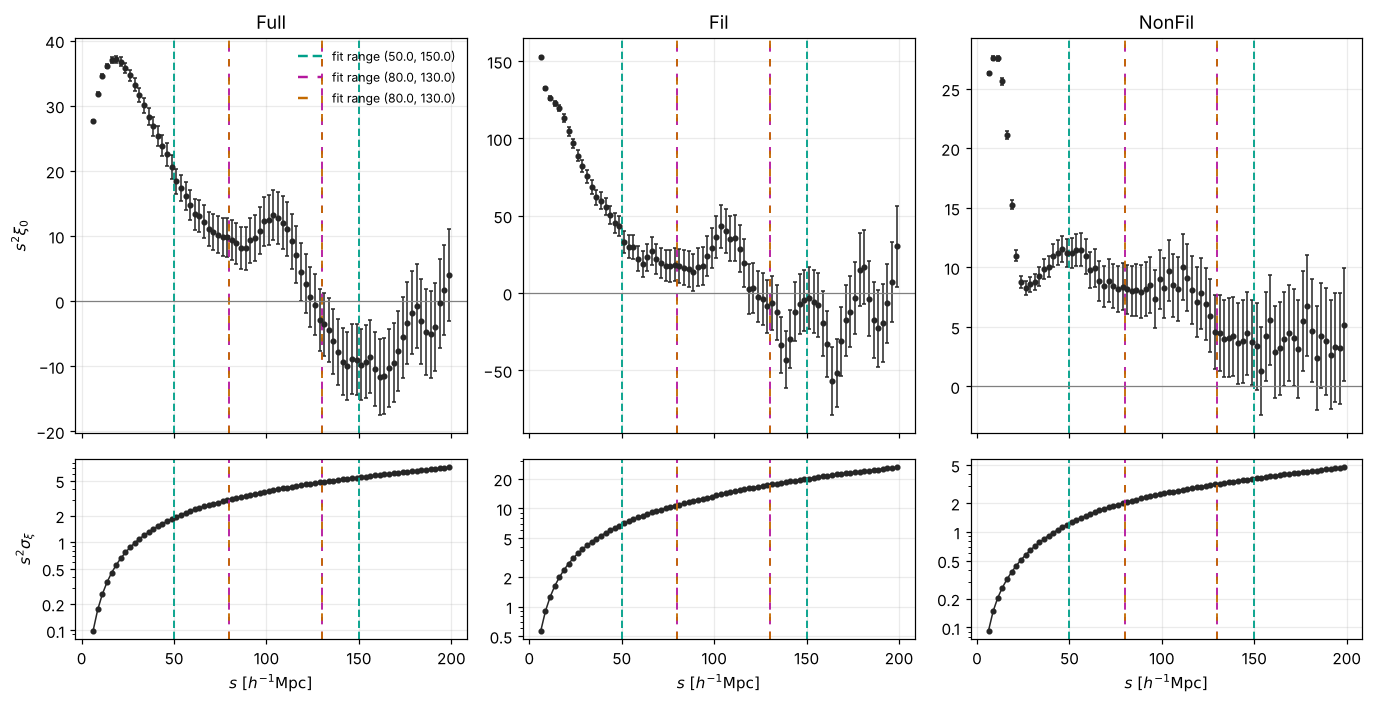

In [2]:
def load_config(c):
    # monopoles, spectra, covariance bias and covariance of every sample of one configuration
    # (desilike_fits, section 1); returns c with spec, samples and data added
    mag, binsep, fit_range = c['mag'], c['binsep'], c['fit_range']
    pk_file = os.path.join(REPO, f'data/processed/pk/box/pk_XISMU_box_mag{mag:.1f}_{split_name}.npz')
    spec = bf.load_spectra(pk_file)
    samples = dict(base_samples)
    for lab in dilution_of:
        n = spec['n_gal'][spec['labels'].index(samples[lab])]
        dil = [l for l, nn in zip(spec['labels'], spec['n_gal']) if l.startswith('FullrandomN-') and nn == n]
        if dil:
            samples[f'Full dil n{lab}'] = dil[0]
    data = {}
    for lab, key in samples.items():
        f = monopole_file(mag, binsep, key)
        if f is None:
            print(f"SKIP {lab}: no monopole file for label '{key}' at bin width {binsep} "
                  f"(run scripts/multidark_analysis.py with mag_max = {mag}, bin_size_2d = {binsep})")
            continue
        s, xi, n_gal = bf.load_monopole(f)
        edges = bf.edges_from_centres(s)
        assert edges[0] <= fit_range[0] and edges[-1] >= fit_range[1], \
            f"{lab}: monopole covers {edges[0]}-{edges[-1]}, fit_range is {fit_range}"
        i_spec = spec['labels'].index(key)
        assert int(spec['n_gal'][i_spec]) == n_gal, f"{lab}: N differs from the spectra file"
        b = bf.estimate_bias_independent(s, xi, edges, n_gal / bf.L_BOX**3, T)['b']
        C = bf.gaussian_cov_pk(edges, spec, [i_spec], [b], lin)
        m = (s >= fit_range[0]) & (s <= fit_range[1])
        data[lab] = dict(s=s, xi=xi, edges=edges, C=C, sig=np.sqrt(np.diag(C)), m=m, n_gal=n_gal, b=b,
                         binsep=binsep, fit_range=fit_range, bb=tuple(c['bb']),
                         file=os.path.basename(f))
        print(f"{lab:<18} N = {n_gal:>8d}   {m.sum():>2d} bins in fit range   b(cov) = {b:.3f}   {os.path.basename(f)}")
    return dict(c, spec=spec, pk_file=pk_file, samples=samples, data=data)

cfgs = []
for c in configs:
    print(f"--- {c['name']}")
    cfgs.append(load_config(c))
    print(f"    spectra file: {os.path.basename(cfgs[-1]['pk_file'])}")

def sample_order():
    # every sample present in any configuration, each random dilution right after the sample whose N it matches
    seen = [l for C in cfgs for l in C['data']]
    out = []
    for lab in base_samples:
        out += [l for l in (lab, f'Full dil n{lab}') if l in seen]
    return out
labs_all = sample_order()
labs_p = [l for l in plot_samples if l in labs_all]

for lab in labs_all:                                   # the configurations share the data and covariance
    for C in cfgs[1:]:
        assert np.array_equal(C['data'][lab]['xi'], cfgs[0]['data'][lab]['xi']) and \
               np.array_equal(C['data'][lab]['C'], cfgs[0]['data'][lab]['C']), f"{lab}: data differ between configurations"
fig, axes = plt.subplots(2, len(labs_p), figsize=(4.2 * len(labs_p), 6.5), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.2, 1)), squeeze=False)
for j, lab in enumerate(labs_p):
    d = cfgs[0]['data'][lab]; s = d['s']                   # all bins of the monopole file (mono_sep)
    axes[0, j].errorbar(s, s**2 * d['xi'], yerr=s**2 * d['sig'], fmt='o', ms=3, capsize=1.5, lw=1, color=DATA)
    axes[1, j].plot(s, s**2 * d['sig'], 'o-', ms=3, lw=1, color=DATA)
    for ic, C in enumerate(cfgs):                          # fit range of each configuration
        for a in axes[:, j]:
            for x in C['fit_range']:
                a.axvline(x, color=CCOL[ic], ls=(0, (4, 2 + 2 * ic)), lw=1.2)
    axes[0, j].axhline(0, color='0.5', lw=0.8)
    axes[0, j].set_title(lab); axes[1, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
    axes[1, j].set_yscale('log')
    axes[1, j].yaxis.set_major_locator(mticker.LogLocator(subs=(1, 2, 5)))
    axes[1, j].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}'))
    axes[1, j].yaxis.set_minor_formatter(mticker.NullFormatter())
axes[0, 0].set_ylabel(r'$s^2\xi_0$'); axes[1, 0].set_ylabel(r'$s^2\sigma_\xi$')
axes[0, 0].legend(handles=[Line2D([], [], color=CCOL[i], ls=(0, (4, 2 + 2 * i)), label=f"fit range {C['fit_range']}")
                           for i, C in enumerate(cfgs)], fontsize=8, frameon=False)
fig.tight_layout(); plt.show()

## 2. The fits

Exactly as in `desilike_fits.ipynb`, section 2 (functions copied; the bin width, fit range and broadband
powers now come with each sample's data: `d['binsep']`, `d['fit_range']`, `d['bb']`): real space (`dbeta` = 0, `sigmas` = 0), isotropic damping
(`sigmapar` = `sigmaper` = Σ), broadband $\sum_{n\in\mathcal P}a_n(s/s_p)^n$ with the powers `bb` of the configuration (introduction), Wallisch no-wiggle, model averaged over each data
bin, Minuit.

The χ² of the α fit includes the Σ prior term ((Σ − Σ_th)/`Sigma_prior_sd`)²; its degrees of freedom are
dof = N_bins + 1 − N_par (N_bins = bins in the fit range, the Gaussian prior counts as one data point,
N_par = parameters varied by desilike). The Σ fit has no prior term and dof = N_bins − N_par.

The Σ interval comes from the profile

$$
\chi^2_{\rm prof}(\Sigma)=\min_{\alpha,\,b_1,\,a_{-2},\,a_{-1},\,a_0}\chi^2(\Sigma,\alpha,b_1,a_{-2},a_{-1},a_0),
\qquad
\boxed{\;\Delta\chi^2(\Sigma)=\chi^2_{\rm prof}(\Sigma)-\chi^2_{\rm min}\;}
$$

written here for $\mathcal P=\{-2,-1,0\}$ (with fewer powers the minimum runs over fewer $a_n$), where $b_1$ is the
amplitude (`b1`), $a_{-2},a_{-1},a_0$ the broadband coefficients (`al0_-2`, `al0_-1`, `al0_0`) and χ²_min the smallest χ²_prof on the grid. The 68% interval is where Δχ²(Σ) ≤ 1 (`edge` when it
reaches the end of `Sigma_free`), and Δχ²(Σ_th) is its value at the Zel'dovich prediction.

In [3]:
def desilike_theory(prior='gauss', only_now=False, bb=(-2, -1, 0)):
    # the BAO model of all fits (one sample); returns the theory and its template.  bb: powers n of the free
    # broadband terms a_n (s/s_p)^n; desilike_fits uses (-2, -1, 0)
    tpl = BAOPowerSpectrumTemplate(z=0., fiducial=cosmo, apmode='qiso', with_now='wallish2018', only_now=only_now)
    th = DampedBAOWigglesTracerCorrelationFunctionMultipoles(ells=(0,), template=tpl, broadband='power')
    P = th.init.params
    P['dbeta'].update(value=0., fixed=True)
    P['sigmas'].update(value=0., fixed=True)
    if prior == 'gauss':
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(dist='norm', loc=Sigma_th, scale=Sigma_prior_sd, limits=[0., 30.]))
    else:
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(limits=list(Sigma_free)))
    P['sigmapar'].update(derived='{sigmaper}')
    for n in range(-2, 3):                      # desilike's broadband powers: -2 ... 2
        if n not in bb:
            P[f'al0_{n}'].update(value=0., fixed=True)
    if only_now:
        P['sigmaper'].update(fixed=True, value=Sigma_th, prior=None)
        tpl.init.params['qiso'].update(fixed=True, value=1.)
    return th, tpl

def desilike_lik(d, prior='gauss', only_now=False):
    th, _ = desilike_theory(prior, only_now, d['bb'])
    m = d['m']
    obs = TracerCorrelationFunctionMultipolesObservable(
        data=d['xi'][m], s=d['s'][m], covariance=d['C'][np.ix_(m, m)],
        slim={0: (d['fit_range'][0], d['fit_range'][1], d['binsep'])}, wmatrix={'resolution': 10}, theory=th)
    return ObservablesGaussianLikelihood(observables=[obs]), obs

def desilike_fit(lik, interval=False):
    prof = MinuitProfiler(lik, seed=42)
    prof.maximize(niterations=5)
    b = prof.profiles.bestfit
    i = int(np.argmax(b.logposterior))
    pars = {p.name: float(b[p.name][i]) for p in lik.varied_params}
    out = dict(prof=prof, pars=pars, chi2=-2 * float(b['loglikelihood'][i]))
    if interval:
        prof.interval(params=['qiso'])
        iv = prof.profiles.interval['qiso']
        lo, hi = pars['qiso'] + iv[0], pars['qiso'] + iv[1]
        # desilike stops the interval at the prior edges (0.8, 1.2): report that as open
        out['lo'] = np.nan if lo <= 0.8 + 1e-3 else lo
        out['hi'] = np.nan if hi >= 1.2 - 1e-3 else hi
    return out

def interval_68(x, dchi2):
    # Delta chi2 = 1 interval around the minimum of a profile, crossings interpolated linearly between
    # grid points; nan on a side where Delta chi2 stays below 1 up to the end of the grid
    i0 = int(np.argmin(dchi2))
    up = [i for i in range(i0, len(x)) if dchi2[i] > 1]
    dn = [i for i in range(i0, -1, -1) if dchi2[i] > 1]
    hi = np.interp(1., dchi2[[up[0] - 1, up[0]]], x[[up[0] - 1, up[0]]]) if up else np.nan
    lo = np.interp(1., dchi2[[dn[0] + 1, dn[0]]], x[[dn[0] + 1, dn[0]]]) if dn else np.nan
    return lo, hi

def sigma_profile(lik, Sigma_best):
    # Delta chi2(Sigma) on a grid over Sigma_free (all other varied parameters refitted at each point), its
    # Delta chi2 = 1 interval and its value at Sigma_th.  lo / hi = nan: the interval reaches the edge of Sigma_free.
    grid = np.union1d(np.arange(Sigma_free[0], Sigma_free[1] + 1e-9, Sigma_step), [Sigma_th, Sigma_best])
    prof = MinuitProfiler(lik, seed=42)
    prof.profile(params=['sigmaper'], grid=grid)
    pr = np.asarray(prof.profiles.profile['sigmaper'])
    S, dchi2 = pr[:, 0], -2 * (pr[:, 1] - pr[:, 1].max())     # flat prior: log-posterior = log-likelihood + const
    lo, hi = interval_68(S, dchi2)
    return dict(S=S, dchi2=dchi2, lo=lo, hi=hi, dchi2_th=float(dchi2[np.argmin(np.abs(S - Sigma_th))]))

def fit_config(C):
    # the three fits and the Sigma profile of every sample of one configuration (desilike_fits, section 2)
    res = {}
    t0 = time.time()
    for lab, d in C['data'].items():
        lik_a, obs_a = desilike_lik(d, 'gauss'); f_a = desilike_fit(lik_a, interval=True)
        lik_S, obs_S = desilike_lik(d, 'flat');  f_S = desilike_fit(lik_S, interval=True)
        lik_n, _ = desilike_lik(d, only_now=True); f_n = desilike_fit(lik_n)
        lik_a(**f_a['pars']); model = np.array(obs_a.flattheory)
        lik_S(**f_S['pars']); model_S = np.array(obs_S.flattheory)
        chi2 = f_a['chi2'] + ((f_a['pars']['sigmaper'] - Sigma_th) / Sigma_prior_sd)**2
        n_par = len(lik_a.varied_params)
        prof_Sig = sigma_profile(lik_S, f_S['pars']['sigmaper'])
        res[lab] = dict(fit=f_a, fit_S=f_S, fit_nw=f_n, lik_a=lik_a, lik_S=lik_S, model=model, model_S=model_S,
                        chi2=chi2, det=f_n['chi2'] - chi2, dof=int(d['m'].sum()) + 1 - n_par, prof_Sig=prof_Sig,
                        dof_S=int(d['m'].sum()) - len(lik_S.varied_params), n_par=n_par)
        print(f"{lab:<18} alpha = {f_a['pars']['qiso']:.4f}   alpha (Sigma free) = {f_S['pars']['qiso']:.4f} "
              f"at Sigma = {f_S['pars']['sigmaper']:.2f}   dchi2(Sigma_th) = {prof_Sig['dchi2_th']:.2f}   "
              f"({time.time() - t0:.0f} s)")
    return res

for C in cfgs:
    print(f"--- {C['name']}")
    C['res'] = fit_config(C)
for C in cfgs:
    lik0 = next(iter(C['res'].values()))['lik_a']
    print(f"{C['name']}: parameters varied in the alpha fit (N_par = {len(lik0.varied_params)}): "
          f"{[p.name for p in lik0.varied_params]}")

--- fit 50-150, bb powers (-2, -1, 0)


Full               alpha = 0.9760   alpha (Sigma free) = 0.9755 at Sigma = 6.10   dchi2(Sigma_th) = 0.24   (20 s)


Fil                alpha = 0.9743   alpha (Sigma free) = 0.9707 at Sigma = 0.00   dchi2(Sigma_th) = 1.26   (38 s)


NonFil             alpha = 0.9513   alpha (Sigma free) = 0.9490 at Sigma = 6.92   dchi2(Sigma_th) = 0.01   (59 s)


Full dil nFil      alpha = 0.9831   alpha (Sigma free) = 0.9874 at Sigma = 10.56   dchi2(Sigma_th) = 0.27   (79 s)


...

Full               alpha = 0.9757   alpha (Sigma free) = 0.9756 at Sigma = 6.20   dchi2(Sigma_th) = 0.18   (14 s)


Fil                alpha = 0.9716   alpha (Sigma free) = 0.9691 at Sigma = 0.03   dchi2(Sigma_th) = 0.86   (27 s)


NonFil             alpha = 0.9311   alpha (Sigma free) = 0.9357 at Sigma = 11.02   dchi2(Sigma_th) = 0.04   (43 s)


Full dil nFil      alpha = 0.9725   alpha (Sigma free) = 0.9709 at Sigma = 5.51   dchi2(Sigma_th) = 0.20   (57 s)


Full dil nNonFil   alpha = 0.9744   alpha (Sigma free) = 0.9745 at Sigma = 5.02   dchi2(Sigma_th) = 0.48   (71 s)
fit 50-150, bb powers (-2, -1, 0): parameters varied in the alpha fit (N_par = 6): ['qiso', 'b1', 'sigmaper', 'al0_-2', 'al0_-1', 'al0_0']
fit 80-130, bb powers (-2, -1, 0): parameters varied in the alpha fit (N_par = 6): ['qiso', 'b1', 'sigmaper', 'al0_-2', 'al0_-1', 'al0_0']
fit 80-130, bb powers (-1, 0): parameters varied in the alpha fit (N_par = 5): ['qiso', 'b1', 'sigmaper', 'al0_-1', 'al0_0']


## 3. Best fits

As `desilike_fits.ipynb`, section 3, one block of rows per configuration (label on the left): data with
errors, the best α-fit model (solid) and the best Σ-free model (dashed), and normalised residuals
(ξ − model)/σ (filled: α fit; open: Σ free). Each model is drawn over its own fit range. Within a column the s²ξ₀
panels of all configurations share the same y range. The bins are correlated, so runs of same-sign residuals are expected.

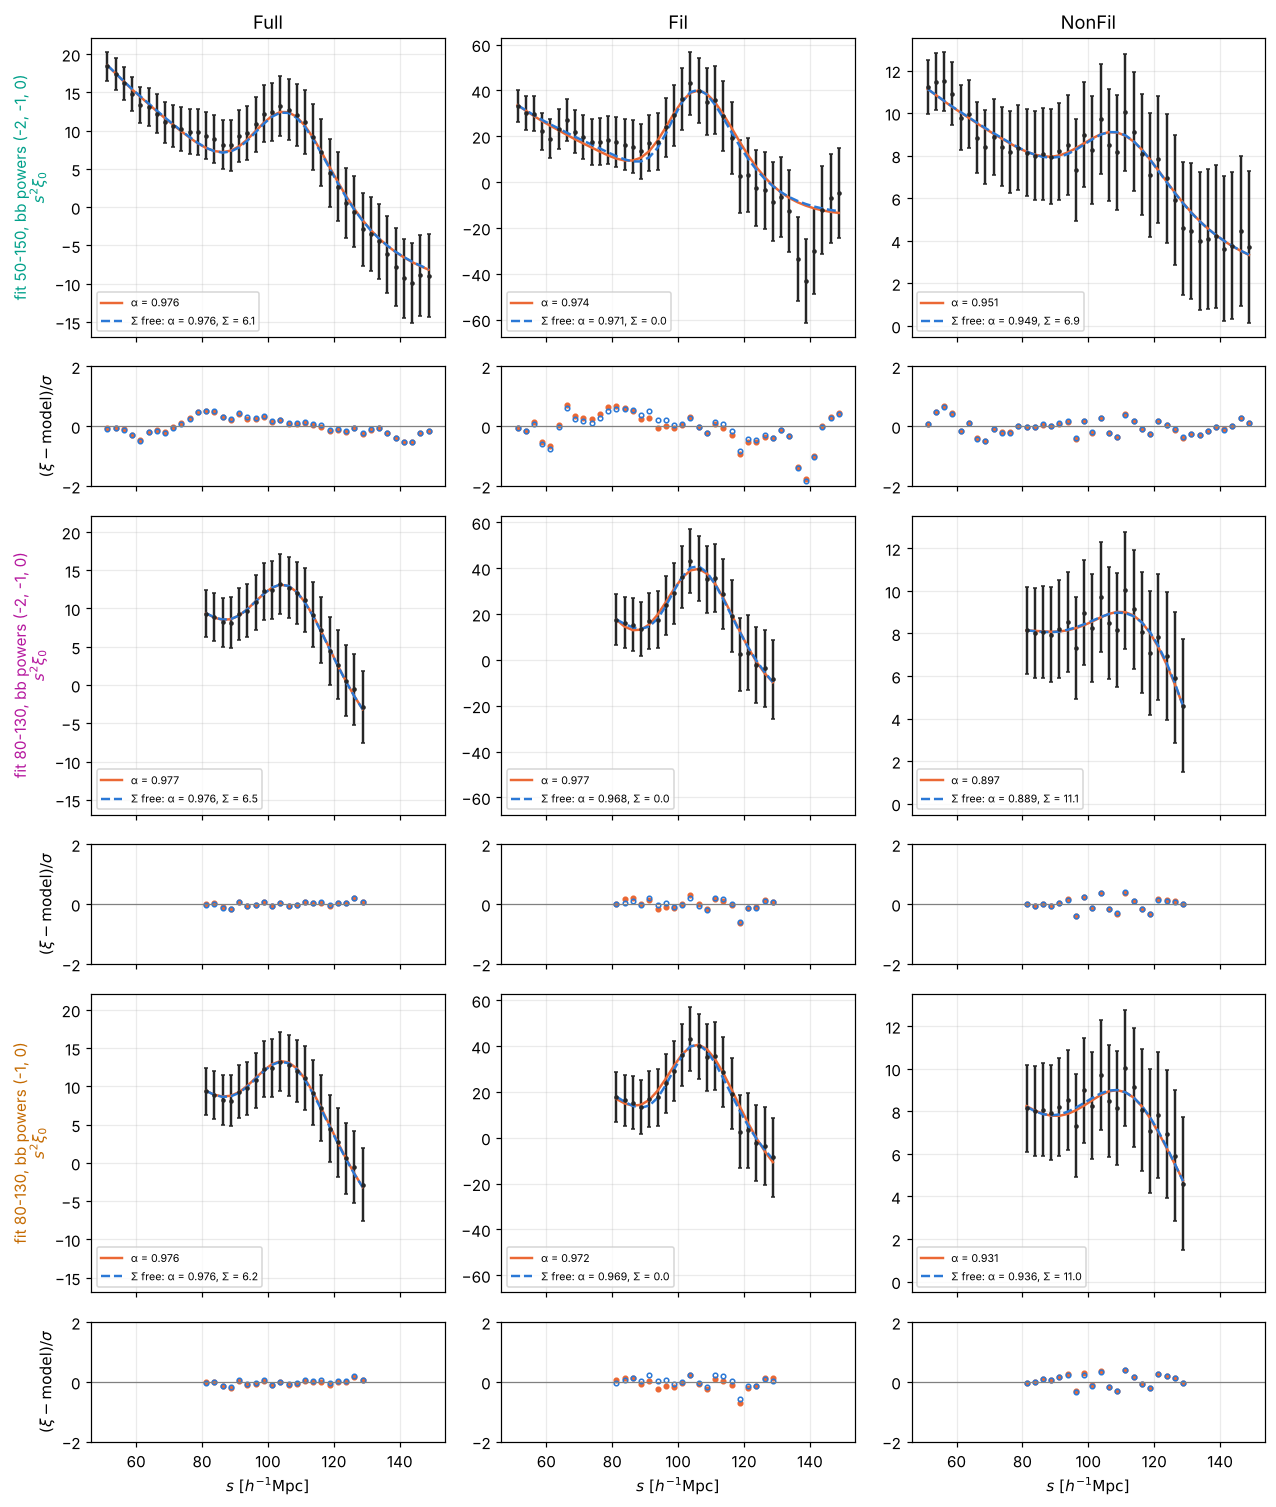

In [4]:
nC = len(cfgs)
fig, axes = plt.subplots(2 * nC, len(labs_p), figsize=(3.9 * len(labs_p), 4.6 * nC), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.5, 1) * nC), squeeze=False)
for j, lab in enumerate(labs_p):
    for ic, C in enumerate(cfgs):
        aT, aR = axes[2 * ic, j], axes[2 * ic + 1, j]
        if lab not in C['data']:
            aT.text(0.5, 0.5, 'no data', transform=aT.transAxes, ha='center'); continue
        d, r = C['data'][lab], C['res'][lab]; s, m, sg = d['s'], d['m'], d['sig']
        aT.errorbar(s[m], s[m]**2 * d['xi'][m], yerr=s[m]**2 * sg[m], fmt='.', ms=4, capsize=1.5, color=DATA)
        aT.plot(s[m], s[m]**2 * r['model'], color=DESI, label=f"α = {r['fit']['pars']['qiso']:.3f}")
        aT.plot(s[m], s[m]**2 * r['model_S'], color=FREE, ls='--',
                label=f"Σ free: α = {r['fit_S']['pars']['qiso']:.3f}, Σ = {r['fit_S']['pars']['sigmaper']:.1f}")
        aR.plot(s[m], (d['xi'][m] - r['model']) / sg[m], 'o', ms=3, color=DESI)
        aR.plot(s[m], (d['xi'][m] - r['model_S']) / sg[m], 'o', ms=3, mfc='none', color=FREE)
        aR.axhline(0, color='0.5', lw=0.8); aR.set_ylim(-2, 2)
        aT.legend(fontsize=7, loc='lower left')
        if ic == 0: aT.set_title(lab)
        if j == 0:
            aT.set_ylabel(f"{C['name']}\n" + r'$s^2\xi_0$', color=CCOL[ic])
            aR.set_ylabel(r'$(\xi-{\rm model})/\sigma$')
    ys = [axes[2 * ic, j].get_ylim() for ic, C in enumerate(cfgs) if lab in C['data']]
    for ic in range(nC):
        axes[2 * ic, j].set_ylim(min(y[0] for y in ys), max(y[1] for y in ys))
for j in range(len(labs_p)):
    axes[-1, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
fig.tight_layout(); plt.show()

## 4. Results per sample

**Tables.** For each configuration, the summary table of `desilike_fits.ipynb` (section 5), same columns:

* α [68%]: α fit, best fit and Δχ² = 1 interval (`open` if it reaches the edge of the α prior, 0.8–1.2);
* α, Σ free [68%]: the same from the Σ fit;
* Σ [68%]: Σ fit, best fit and the Δχ²(Σ) ≤ 1 interval (`edge` if it reaches the end of `Sigma_free`);
* Δχ²(Σ_th); χ²/dof of the α fit (prior term included) and of the Σ fit; Δχ²_det.

Then, for each other configuration, the shift of each value from the first configuration of `configs`
(that configuration minus the first), for the samples present in both. No error is attached to these shifts (see the introduction).

**Figure.** One panel per column of the table, samples on the x axis (each random dilution next to the
sample whose N it matches, grey label), colour and marker shape = configuration. Filled: α fit (Gaussian Σ
prior); open: Σ fit (flat prior), shifted right. A side of an interval that is `open` / `edge` in the table is
dotted up to the edge of the panel / of `Sigma_free`. In the χ²/dof panel the shaded bands are
1 ± √(2/dof) of each configuration's α fit (the expected scatter of χ²/dof if model and covariance are right).


fit 50-150, bb powers (-2, -1, 0)
sample            | alpha [68%]              | alpha, Sigma free [68%]  | Sigma [68%]          | dchi2(Sig_th) | chi2/dof   | chi2/dof Sfree| dchi2_det
-------------------------------------------------------------------------------------------------------------------------------------------------------
Full              | 0.9760 [0.958, 0.995]    | 0.9755 [0.958, 0.994]    | 6.10 [2.66, 9.80]    |          0.24 |  22.7/35   |  22.6/34      |     15.30
Fil               | 0.9743 [0.951, 1.002]    | 0.9707 [0.950, 0.992]    | 0.00 [edge, 6.97]    |          1.26 |  31.2/35   |  30.5/34      |      8.53
Full dil nFil     | 0.9831 [0.955, 1.014]    | 0.9874 [0.957, 1.021]    | 10.56 [4.08, 15.39]  |          0.27 |  20.9/35   |  20.8/34      |      8.93
NonFil            | 0.9513 [0.877, 1.038]    | 0.9490 [0.877, 1.050]    | 6.92 [edge, edge]    |          0.01 |  23.8/35   |  23.8/34      |      1.64
Full dil nNonFil  | 0.9772 [0.958, 1.000]    | 0.9757

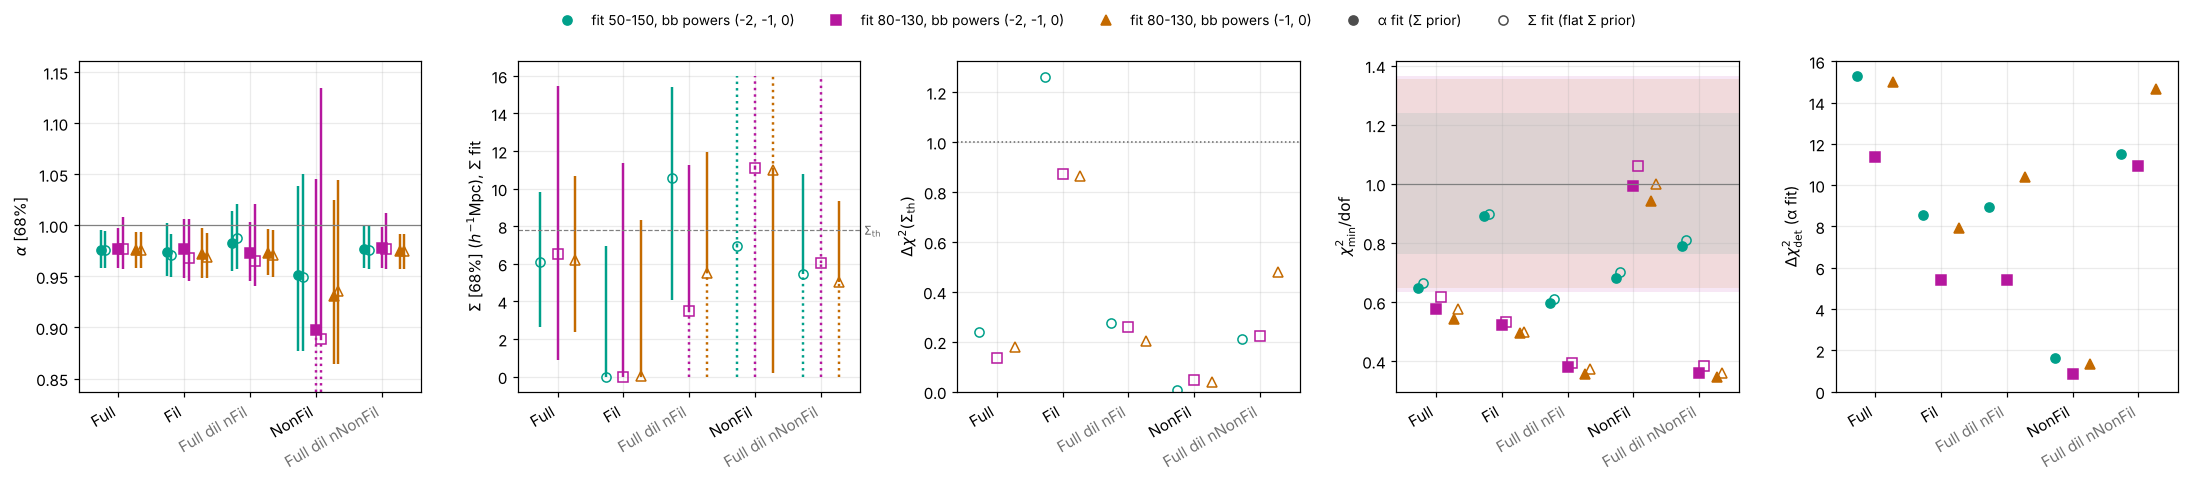

In [5]:
def fmt_a(a, lo, hi):
    f = lambda x: 'open' if not np.isfinite(x) else f'{x:.3f}'
    return f"{a:.4f} [{f(lo)}, {f(hi)}]"

def fmt_S(S, lo, hi):
    f = lambda x: 'edge' if not np.isfinite(x) else f'{x:.2f}'
    return f"{S:.2f} [{f(lo)}, {f(hi)}]"

hdr = (f"{'sample':<18}| {'alpha [68%]':<25}| {'alpha, Sigma free [68%]':<25}| {'Sigma [68%]':<21}| {'dchi2(Sig_th)':>13} | "
       f"{'chi2/dof':<11}| {'chi2/dof Sfree':<14}| {'dchi2_det':>9}")
for C in cfgs:
    print(f"\n{C['name']}"); print(hdr); print('-' * len(hdr))
    for lab in [l for l in labs_all if l in C['res']]:
        r = C['res'][lab]; f, fS, pS = r['fit'], r['fit_S'], r['prof_Sig']
        print(f"{lab:<18}| {fmt_a(f['pars']['qiso'], f['lo'], f['hi']):<25}| "
              f"{fmt_a(fS['pars']['qiso'], fS['lo'], fS['hi']):<25}| {fmt_S(fS['pars']['sigmaper'], pS['lo'], pS['hi']):<21}| "
              f"{pS['dchi2_th']:>13.2f} | "
              f"{r['chi2']:>5.1f}/{r['dof']:<5d}| {fS['chi2']:>5.1f}/{r['dof_S']:<8d}| {r['det']:>9.2f}")

# shifts of each configuration from the first one (that configuration minus the first)
hw = lambda f: 0.5 * (f['hi'] - f['lo'])
fh = lambda x: '  open' if not np.isfinite(x) else f'{x:6.3f}'
C1 = cfgs[0]
for C2 in cfgs[1:]:
    print(f"\nshift ({C2['name']}) - ({C1['name']}), samples in both")
    hdr = (f"{'sample':<18}| {'d alpha':>8} | {'d alpha Sfree':>13} | {'d Sigma':>8} | {'d dchi2(Sig_th)':>15} | "
           f"{'d dchi2_det':>11} | {'half-width alpha: 1st -> this':>29}")
    print(hdr); print('-' * len(hdr))
    for lab in [l for l in labs_all if l in C1['res'] and l in C2['res']]:
        r1, r2 = C1['res'][lab], C2['res'][lab]
        da = r2['fit']['pars']['qiso'] - r1['fit']['pars']['qiso']
        daS = r2['fit_S']['pars']['qiso'] - r1['fit_S']['pars']['qiso']
        dS = r2['fit_S']['pars']['sigmaper'] - r1['fit_S']['pars']['sigmaper']
        dth = r2['prof_Sig']['dchi2_th'] - r1['prof_Sig']['dchi2_th']
        dd = r2['det'] - r1['det']
        print(f"{lab:<18}| {da:>+8.4f} | {daS:>+13.4f} | {dS:>+8.2f} | {dth:>+15.2f} | {dd:>+11.2f} | "
              f"{fh(hw(r1['fit'])):>17} -> {fh(hw(r2['fit']))}")

# ---- figure ----
def draw_interval(ax, x, v, lo, hi, color, filled, edge_lo, edge_hi, marker='o', label=None):
    # point with its 68% interval; a side that reaches a prior edge (nan in the table) is dotted up to edge_lo / edge_hi
    ax.plot(x, v, marker, color=color, mfc=color if filled else 'none', label=label)
    for end, edge in ((lo, edge_lo), (hi, edge_hi)):
        ok = np.isfinite(end)
        ax.vlines(x, *sorted((v, end if ok else edge)), color=color, ls='-' if ok else ':')

x = np.arange(len(labs_all))
off = np.linspace(-0.27, 0.27, nC) if nC > 1 else np.zeros(1)   # x offset of each configuration
dx = 0.07                                                      # Sigma-free point, right of the alpha-fit point
fig, axes = plt.subplots(1, 5, figsize=(20, 4.4))
aA, aS, aT, aC, aD = axes
fin = [v for C in cfgs for r in C['res'].values() for kk in ('fit', 'fit_S')
       for v in (r[kk]['pars']['qiso'], r[kk]['lo'], r[kk]['hi']) if np.isfinite(v)] + [1.0]
pad = 0.1 * (max(fin) - min(fin)); ylo, yhi = min(fin) - pad, max(fin) + pad
for ic, C in enumerate(cfgs):
    col, mk = CCOL[ic], CMRK[ic]
    for j, lab in enumerate(labs_all):
        if lab not in C['res']: continue
        r = C['res'][lab]; f, fS, pS = r['fit'], r['fit_S'], r['prof_Sig']
        xj = j + off[ic]
        draw_interval(aA, xj, f['pars']['qiso'], f['lo'], f['hi'], col, True, ylo, yhi, mk)
        draw_interval(aA, xj + dx, fS['pars']['qiso'], fS['lo'], fS['hi'], col, False, ylo, yhi, mk)
        draw_interval(aS, xj, fS['pars']['sigmaper'], pS['lo'], pS['hi'], col, False, *Sigma_free, mk)
        aT.plot(xj, pS['dchi2_th'], mk, color=col, mfc='none')
        aC.plot(xj, r['chi2'] / r['dof'], mk, color=col)
        aC.plot(xj + dx, fS['chi2'] / r['dof_S'], mk, color=col, mfc='none')
        aD.plot(xj, r['det'], mk, color=col)
    dof = [r['dof'] for r in C['res'].values()][0]
    aC.axhspan(1 - np.sqrt(2 / dof), 1 + np.sqrt(2 / dof), color=col, alpha=0.10, lw=0)
aA.set_ylim(ylo, yhi); aA.axhline(1, color='0.5', lw=0.8); aA.set_ylabel(r'$\alpha$ [68%]')
aS.axhline(Sigma_th, color='0.5', ls='--', lw=0.8); aS.set_ylabel(r'$\Sigma$ [68%] ($h^{-1}$Mpc), Σ fit')
aS.text(1.0, Sigma_th, r' $\Sigma_{\rm th}$', transform=aS.get_yaxis_transform(), va='center', fontsize=8, color='0.4')
aT.axhline(1, color='0.4', ls=':', lw=1); aT.set_ylim(bottom=0); aT.set_ylabel(r'$\Delta\chi^2(\Sigma_{\rm th})$')
aC.axhline(1, color='0.5', lw=0.8); aC.set_ylabel(r'$\chi^2_{\rm min}/{\rm dof}$')
aD.set_ylim(bottom=0); aD.set_ylabel(r'$\Delta\chi^2_{\rm det}$ (α fit)')
for a in axes:
    a.set_xticks(x); a.set_xticklabels(labs_all, rotation=30, ha='right'); a.set_xlim(-0.6, len(labs_all) - 0.4)
    for t in a.get_xticklabels():
        if t.get_text().startswith('Full dil'): t.set_color('0.45')
handles = [Line2D([], [], color=CCOL[i], marker=CMRK[i], ls='', label=C['name']) for i, C in enumerate(cfgs)]
handles += [Line2D([], [], color='0.3', marker='o', ls='', label='α fit (Σ prior)'),
            Line2D([], [], color='0.3', marker='o', mfc='none', ls='', label='Σ fit (flat Σ prior)')]
fig.legend(handles=handles, loc='upper center', ncol=len(handles), frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

## 5. Differences between samples: Δα and ΔΣ

As `desilike_fits.ipynb`, section 7, for each configuration: Δα = α_A − α_B and ΔΣ = Σ_A − Σ_B for the pairs
in `pairs`, from joint fits of the two samples with their joint covariance

$$
\chi^2=(\mathbf d-\mathbf m)^{\rm T}\,\mathsf C^{-1}(\mathbf d-\mathbf m),\qquad
\mathbf d=\begin{pmatrix}\hat\xi_{0,A}\\ \hat\xi_{0,B}\end{pmatrix},\qquad
\mathsf C=\begin{pmatrix}\mathsf C_{AA}&\mathsf C_{AB}\\ \mathsf C_{BA}&\mathsf C_{BB}\end{pmatrix}
$$

where $\hat\xi_{0,A}$, $\hat\xi_{0,B}$ are the two monopoles in the fit range, $\mathbf m$ the two models and
$\mathsf C$ = `bf.gaussian_cov_pk` for both samples together (cross block from the measured cross spectrum).
Each sample keeps its own parameters, except that B's parameter of interest is written through the
difference ($\alpha_B=\alpha_A-\Delta\alpha$ with the Gaussian Σ prior on each sample; $\Sigma_B=\Sigma_A-\Delta\Sigma$ with the
flat prior `Sigma_free` on both). For each difference Δ:

$$
\boxed{\;\Delta\chi^2(\Delta)=\chi^2_{\rm prof}(\Delta)-\chi^2_{\rm min}\;}
$$

with $\chi^2_{\rm prof}(\Delta)$ the minimum of χ² at fixed Δ (all other parameters of both samples refitted) and
$\chi^2_{\rm min}$ its smallest value. **Δ [68%]**: best fit and the Δχ²(Δ) ≤ 1 interval (`edge`: it reaches the end
of the grid). **Δχ²(0)**: the cost of forcing the two samples to the same value ($\sqrt{\Delta\chi^2(0)}$ ≈ the
significance in σ for a Gaussian likelihood).

The cell prints the table of each configuration, then draws Δα and ΔΣ with their intervals (colour and marker
= configuration), and the Δχ² profiles: one column per pair, Δα on top and ΔΣ below, colour = configuration. The figures are in
the next cell, so they can be redrawn without redoing the joint fits.

In [6]:
def joint_setup(C, A, B, tie):
    # joint chi2 of samples A and B of configuration C for tie = 'alpha' (alpha_B = alpha_A - Delta, Gaussian
    # Sigma priors of the alpha fit) or 'Sigma' (Sigma_B = Sigma_A - Delta, flat priors Sigma_free).  The models are
    # desilike_lik's, i.e. exactly those of the single fits; only the chi2 is joint.  (desilike_fits, section 7)
    data, res, spec, samples = C['data'], C['res'], C['spec'], C['samples']
    dA, dB = data[A], data[B]
    assert np.allclose(dA['edges'], dB['edges']) and np.array_equal(dA['m'], dB['m']), f"{A}, {B}: different bins"
    nb = len(dA['s'])
    Cj = bf.gaussian_cov_pk(dA['edges'], spec, [spec['labels'].index(samples[A]), spec['labels'].index(samples[B])],
                            [dA['b'], dB['b']], lin)
    idx = np.concatenate([np.nonzero(dA['m'])[0], nb + np.nonzero(dB['m'])[0]])
    Cinv = np.linalg.inv(Cj[np.ix_(idx, idx)])
    dvec = np.concatenate([dA['xi'][dA['m']], dB['xi'][dB['m']]])
    model = {X: desilike_lik(data[X], 'gauss' if tie == 'alpha' else 'flat') for X in (A, B)}
    pnames = [p.name for p in model[A][0].varied_params]           # per-sample parameters (same for A and B)
    key = {'alpha': 'qiso', 'Sigma': 'sigmaper'}[tie]

    def chi2(pA, pB):
        r = []
        for X, p in ((A, pA), (B, pB)):
            lik, obs = model[X]; lik(**p); r.append(np.array(obs.flattheory))
        r = dvec - np.concatenate(r)
        c = r @ Cinv @ r
        if tie == 'alpha':                                           # the Gaussian Sigma prior on each sample
            c += sum(((p['sigmaper'] - Sigma_th) / Sigma_prior_sd)**2 for p in (pA, pB))
        return float(c)

    # free parameters: A's, B's except the tied one, and Delta; start from the single fits (section 2)
    start = {f'A {n}': v for n, v in res[A]['fit' if tie == 'alpha' else 'fit_S']['pars'].items()}
    start.update({f'B {n}': v for n, v in res[B]['fit' if tie == 'alpha' else 'fit_S']['pars'].items() if n != key})
    start['Delta'] = start[f'A {key}'] - res[B]['fit' if tie == 'alpha' else 'fit_S']['pars'][key]
    names = list(start)

    def fcn(*x):
        v = dict(zip(names, x))
        pA = {n: v[f'A {n}'] for n in pnames}
        pB = {n: (v[f'A {key}'] - v['Delta'] if n == key else v[f'B {n}']) for n in pnames}
        return chi2(pA, pB)

    # limits: alpha in (0.8, 1.2) and Sigma in Sigma_free (alpha fit: (0, 30)) for BOTH samples, through the tie
    lim = {'qiso': (0.8, 1.2), 'sigmaper': Sigma_free if tie == 'Sigma' else (0., 30.)}

    def minimise(delta=None):
        m = Minuit(fcn, *[start[n] for n in names], name=names)
        m.errordef = Minuit.LEAST_SQUARES
        for n in pnames:
            if n in lim:
                m.limits[f'A {n}'] = lim[n]
                if n != key: m.limits[f'B {n}'] = lim[n]
        lo, hi = lim[key]
        if delta is None:
            m.limits['Delta'] = (lo - hi, hi - lo)
        else:                                                        # Delta fixed: keep B's tied parameter in range
            m.values['Delta'] = delta; m.fixed['Delta'] = True
            m.limits[f'A {key}'] = (max(lo, lo + delta), min(hi, hi + delta))
            m.values[f'A {key}'] = np.clip(m.values[f'A {key}'], *m.limits[f'A {key}'])
        m.migrad()
        if not m.valid: m.migrad()
        start.update(zip(names, m.values))                           # warm start for the next grid point
        return m.fval, float(m.values['Delta'])
    return minimise

def delta_profile(C, A, B, tie, grid):
    # best fit of Delta, profile Delta chi2 on the grid (+ 0 and the best fit), 68% interval
    minimise = joint_setup(C, A, B, tie)
    chi2_best, best = minimise()
    x = np.union1d(grid, [0., best])
    x = x[(x >= grid[0]) & (x <= grid[-1]) | np.isclose(x, best)]
    i0 = int(np.argmin(np.abs(x - best)))
    c = np.full(len(x), np.nan)
    for order in (range(i0, len(x)), range(i0 - 1, -1, -1)):         # walk out from the best fit (warm starts)
        minimise(best)
        for i in order:
            c[i] = minimise(x[i])[0]
    dchi2 = c - min(c.min(), chi2_best)
    lo, hi = interval_68(x, dchi2)
    return dict(best=best, x=x, dchi2=dchi2, lo=lo, hi=hi, dchi2_0=float(dchi2[np.argmin(np.abs(x))]))

def fmt_d(r, f):
    g = lambda x: 'edge' if not np.isfinite(x) else format(x, f)
    return f"{format(r['best'], f)} [{g(r['lo'])}, {g(r['hi'])}]"

if do_differences:
    grids = {'alpha': np.arange(-dalpha_max, dalpha_max + 1e-9, dalpha_step),
             'Sigma': np.arange(-Sigma_free[1], Sigma_free[1] + 1e-9, dSigma_step)}
    for C in cfgs:
        print(f"--- {C['name']}")
        C['diff'] = {}
        t0 = time.time()
        for A, B in pairs:
            if A not in C['data'] or B not in C['data']:
                print(f"SKIP {A} - {B}: sample not loaded"); continue
            C['diff'][(A, B)] = {tie: delta_profile(C, A, B, tie, grids[tie]) for tie in ('alpha', 'Sigma')}
            r = C['diff'][(A, B)]
            print(f"{A + ' - ' + B:<26} Delta alpha = {r['alpha']['best']:+.4f}   Delta Sigma = {r['Sigma']['best']:+.2f}   "
                  f"({time.time() - t0:.0f} s)")

    hdr = f"{'A - B':<26}| {'Delta alpha [68%]':<28}| {'dchi2(0)':>8} | {'Delta Sigma [68%]':<24}| {'dchi2(0)':>8}"
    for C in cfgs:
        print(f"\n{C['name']}"); print(hdr); print('-' * len(hdr))
        for (A, B), r in C['diff'].items():
            print(f"{A + ' - ' + B:<26}| {fmt_d(r['alpha'], '+.4f'):<28}| {r['alpha']['dchi2_0']:>8.2f} | "
                  f"{fmt_d(r['Sigma'], '+.2f'):<24}| {r['Sigma']['dchi2_0']:>8.2f}")

else:
    print("do_differences = False: section 5 skipped")

--- fit 50-150, bb powers (-2, -1, 0)


Fil - Full dil nFil        Delta alpha = -0.0034   Delta Sigma = -7.46   (86 s)


NonFil - Full dil nNonFil  Delta alpha = -0.0271   Delta Sigma = +1.30   (155 s)


Fil - NonFil               Delta alpha = +0.0217   Delta Sigma = -7.07   (214 s)


Fil - Full                 Delta alpha = -0.0013   Delta Sigma = -6.61   (303 s)


...

Fil - Full dil nFil        Delta alpha = -0.0011   Delta Sigma = -5.59   (73 s)


NonFil - Full dil nNonFil  Delta alpha = -0.0419   Delta Sigma = +5.67   (136 s)


Fil - NonFil               Delta alpha = +0.0408   Delta Sigma = -10.96   (197 s)


Fil - Full                 Delta alpha = -0.0042   Delta Sigma = -6.30   (281 s)


NonFil - Full              Delta alpha = -0.0433   Delta Sigma = +4.53   (345 s)

fit 50-150, bb powers (-2, -1, 0)
A - B                     | Delta alpha [68%]           | dchi2(0) | Delta Sigma [68%]       | dchi2(0)
-------------------------------------------------------------------------------------------------------
Fil - Full dil nFil       | -0.0034 [-0.0273, +0.0200]  |     0.02 | -7.46 [-14.40, -2.78]   |     2.54
NonFil - Full dil nNonFil | -0.0271 [-0.1058, +0.0636]  |     0.12 | +1.30 [-10.38, +13.80]  |     0.01
Fil - NonFil              | +0.0217 [-0.0669, +0.1007]  |     0.08 | -7.07 [edge, +6.15]     |     0.18
Fil - Full                | -0.0013 [-0.0194, +0.0185]  |     0.01 | -6.61 [-9.20, -1.18]    |     1.66
NonFil - Full             | -0.0286 [-0.1058, +0.0592]  |     0.14 | +0.49 [-9.58, +11.96]   |     0.00

fit 80-130, bb powers (-2, -1, 0)
A - B                     | Delta alpha [68%]           | dchi2(0) | Delta Sigma [68%]       | dchi2(0)
-----------------

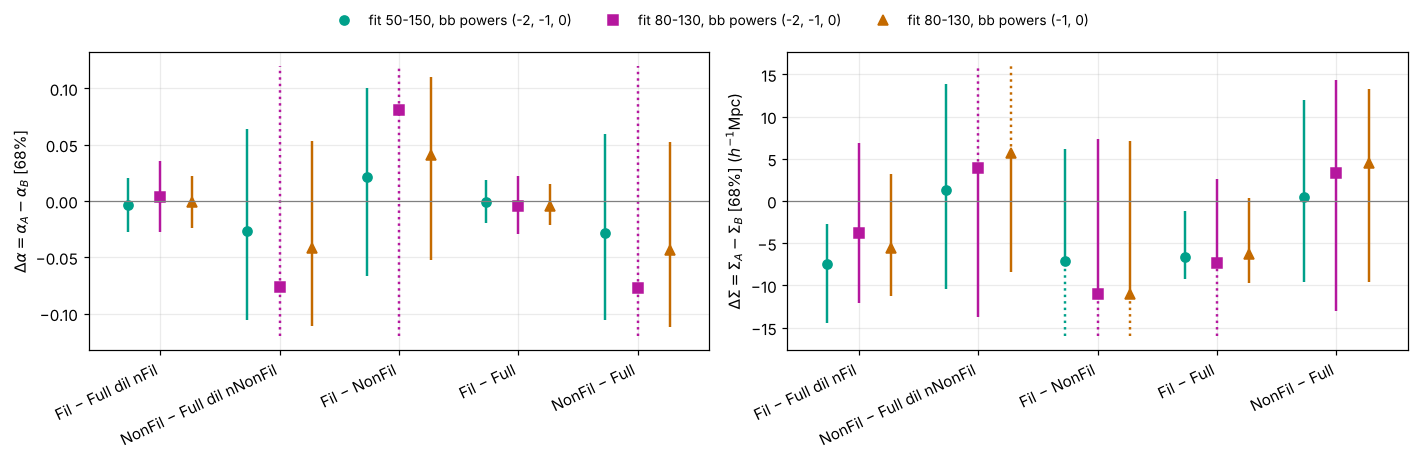

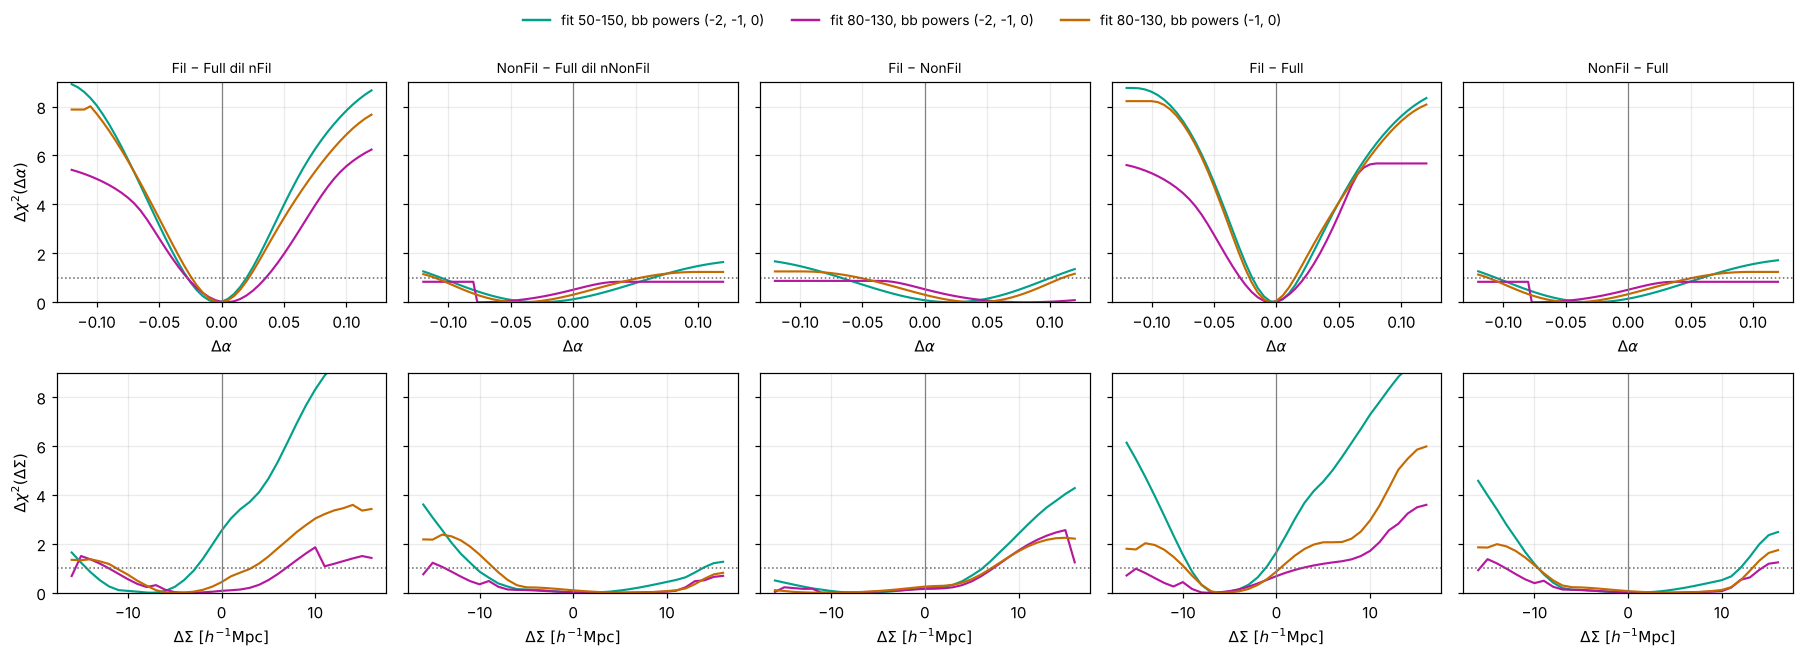

In [ ]:
if do_differences:
    # Delta alpha and Delta Sigma with their 68% intervals, per pair and configuration
    pl = [p for p in pairs if any(p in C['diff'] for C in cfgs)]
    xp = np.arange(len(pl))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ic, C in enumerate(cfgs):
        for j, p in enumerate(pl):
            if p not in C['diff']: continue
            for ax, tie, g in zip(axes, ('alpha', 'Sigma'), (grids['alpha'], grids['Sigma'])):
                r = C['diff'][p][tie]
                draw_interval(ax, j + off[ic], r['best'], r['lo'], r['hi'], CCOL[ic], True, g[0], g[-1], CMRK[ic])
    for ax, yl in zip(axes, (r'$\Delta\alpha=\alpha_A-\alpha_B$ [68%]', r'$\Delta\Sigma=\Sigma_A-\Sigma_B$ [68%] ($h^{-1}$Mpc)')):
        ax.axhline(0, color='0.5', lw=0.8); ax.set_ylabel(yl)
        ax.set_xticks(xp); ax.set_xticklabels([f'{a} − {b}' for a, b in pl], rotation=25, ha='right')
        ax.set_xlim(-0.6, len(pl) - 0.4)
    fig.legend(handles=[Line2D([], [], color=CCOL[i], marker=CMRK[i], ls='', label=C['name']) for i, C in enumerate(cfgs)],
               loc='upper center', ncol=nC, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

    # the Delta chi2 profiles: one column per pair, Delta alpha (top) and Delta Sigma (bottom), colour = configuration
    fig, axes = plt.subplots(2, len(pl), figsize=(3.3 * len(pl), 6), sharey=True, squeeze=False)
    for j, p in enumerate(pl):
        for ic, C in enumerate(cfgs):
            if p not in C['diff']: continue
            for i, tie in enumerate(('alpha', 'Sigma')):
                r = C['diff'][p][tie]
                axes[i, j].plot(r['x'], r['dchi2'], color=CCOL[ic], lw=1.4)
        axes[0, j].set_title(f'{p[0]} − {p[1]}', fontsize=9)
        axes[0, j].set_xlabel(r'$\Delta\alpha$'); axes[1, j].set_xlabel(r'$\Delta\Sigma\ [h^{-1}{\rm Mpc}]$')
    for a in axes.flat:
        a.axhline(1, color='0.4', ls=':', lw=1); a.axvline(0, color='0.5', lw=0.8); a.set_ylim(0, 9)
    axes[0, 0].set_ylabel(r'$\Delta\chi^2(\Delta\alpha)$'); axes[1, 0].set_ylabel(r'$\Delta\chi^2(\Delta\Sigma)$')
    fig.legend(handles=[Line2D([], [], color=CCOL[i], label=C['name']) for i, C in enumerate(cfgs)],
               loc='upper center', ncol=nC, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()
else:
    print("do_differences = False: no figures")